# Análisis del haz — oclusor chico
Ejecutar en orden. La malla XY debe coincidir con los archivos de PHITS. Las predicciones a 110 y 120 cm no son simulaciones nuevas.

## 1. Archivos y malla
Comprobar la ruta impresa antes de continuar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path
from scipy.optimize import curve_fit, brentq
from scipy.interpolate import PchipInterpolator
from IPython.display import display
carpeta = Path('..') / 'out'
archivos = [(33.94, 'track_xy_antes_oclusor.out'), (45.0, 'track_xy_despues_oclusor.out'), (66.8, 'track_xy_entre_oc_y_pouch.out'), (80.0, 'track_xy_antes_pouch.out'), (98.48, 'track_xy_pouch.out'), (100.96, 'track_xy_piso.out')]
xmin, xmax, xdel = (-10, 10, 0.3)
ymin, ymax, ydel = (-15, 15, 0.3)
print('Directorio de lectura:', carpeta.resolve())
for z, nombre in archivos:
    archivo = (carpeta / nombre).resolve()
    print(f'{z:g} cm: {archivo}')
    if not archivo.is_file():
        raise FileNotFoundError(archivo)


Directorio de lectura: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out
33.94 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_antes_oclusor.out
45 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_despues_oclusor.out
66.8 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_entre_oc_y_pouch.out
80 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_antes_pouch.out
98.48 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_pouch.out
100.96 cm: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\track_xy_piso.out


## 2. Lectura y ajuste
Se extraen los cortes más cercanos al origen. Se ajustan dos gaussianas simétricas a los perfiles posteriores al oclusor, dentro de ±8 cm.

In [2]:
def leer_ttrack(filename):
    with open(filename, 'r', errors='replace') as f:
        lines = f.readlines()
    nx = ny = inicio = None
    for i, line in enumerate(lines):
        if 'nx =' in line and 'ny =' in line:
            mx = re.search('\\bnx\\s*=\\s*(\\d+)', line)
            my = re.search('\\bny\\s*=\\s*(\\d+)', line)
            if mx and my:
                nx = int(mx.group(1))
                ny = int(my.group(1))
        if line.strip().startswith('hc:') and inicio is None:
            inicio = i + 1
    if nx is None or ny is None or inicio is None:
        raise ValueError(f'No se pudieron leer nx, ny o hc: de {filename}')
    patron = '[-+]?(?:\\d+(?:\\.\\d*)?|\\.\\d+)(?:[EeDd][-+]?\\d+)?'
    datos = []
    for line in lines[inicio:]:
        if line.strip().startswith('#'):
            break
        for numero in re.findall(patron, line):
            datos.append(float(numero.replace('D', 'E').replace('d', 'e')))
        if len(datos) >= nx * ny:
            break
    datos = np.asarray(datos[:nx * ny], dtype=float)
    if datos.size != nx * ny:
        raise ValueError(f'{filename}: se esperaban {nx * ny} valores y se leyeron {datos.size}')
    flujo = datos.reshape(ny, nx)[::-1, :]
    return (flujo, nx, ny)

def dos_gaussianas(u, A, a, sigma, B):
    return A * (np.exp(-(u - a) ** 2 / (2 * sigma ** 2)) + np.exp(-(u + a) ** 2 / (2 * sigma ** 2))) + B

def ajustar_gaussianas(coord, perfil):
    mascara = (np.abs(coord) <= 8) & np.isfinite(perfil)
    u = np.asarray(coord[mascara])
    v = np.asarray(perfil[mascara])
    escala = float(np.max(v))
    if escala <= 0:
        raise ValueError('El perfil no tiene fluencia positiva')
    v_n = v / escala
    mejor = None
    mejor_rmse = np.inf
    for a0 in [0.4, 1.0, 1.5, 2.5, 3.5]:
        for sigma0 in [0.6, 1.2, 2.0, 3.5, 5.0]:
            try:
                p, _ = curve_fit(dos_gaussianas, u, v_n, p0=[0.7, a0, sigma0, 0.01], bounds=([0, 0, 0.1, 0], [3, 8, 12, 0.25]), maxfev=20000)
                pred = dos_gaussianas(u, *p)
                rmse = float(np.sqrt(np.mean((v_n - pred) ** 2)))
                if rmse < mejor_rmse:
                    mejor = p
                    mejor_rmse = rmse
            except (RuntimeError, ValueError):
                continue
    if mejor is None:
        raise RuntimeError('No se pudo ajustar el perfil')
    pred = dos_gaussianas(u, *mejor)
    ss_res = float(np.sum((v_n - pred) ** 2))
    ss_tot = float(np.sum((v_n - np.mean(v_n)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    A_n, a, sigma, B_n = mejor
    u_fino = np.linspace(-8, 8, 1001)
    pred_fino = dos_gaussianas(u_fino, *mejor)
    R_modelo = float(dos_gaussianas(0, *mejor) / np.max(pred_fino))
    return {'a': float(a), 'sigma': float(sigma), 'A': float(A_n * escala), 'B': float(B_n * escala), 'A_norm': float(A_n), 'B_norm': float(B_n), 'escala': escala, 'RMSE': mejor_rmse, 'R2': r2, 'R_modelo': R_modelo}


In [3]:
resultados = []
for z, nombre in archivos:
    flujo, nx, ny = leer_ttrack(carpeta / nombre)
    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel
    ix0 = int(np.argmin(np.abs(x)))
    iy0 = int(np.argmin(np.abs(y)))
    px = flujo[iy0, :]
    py = flujo[:, ix0]
    resultados.append({'z': z, 'archivo': nombre, 'flujo': flujo, 'x': x, 'y': y, 'perfil_x': px, 'perfil_y': py, 'r_x': float(px[ix0] / np.max(px)), 'r_y': float(py[iy0] / np.max(py)), 'centro_x': float(x[ix0]), 'centro_y': float(y[iy0])})
print(f'Se leyeron {len(resultados)} mapas XY')
print(f"Centro del bin de X: {resultados[0]['centro_x']:.3f} cm")
print(f"Centro del bin de Y: {resultados[0]['centro_y']:.3f} cm")
ajustes = {'x': [], 'y': []}
for r in resultados:
    if r['z'] < 40:
        continue
    for eje in ('x', 'y'):
        parametros = ajustar_gaussianas(r[eje], r[f'perfil_{eje}'])
        ajustes[eje].append({**parametros, 'z': r['z'], 'coord': r[eje], 'perfil': r[f'perfil_{eje}'], 'R_PHITS': r[f'r_{eje}'], 'G': parametros['a'] - parametros['sigma']})
print('Ajustes completados en X e Y para las cinco posiciones posteriores al oclusor')


Se leyeron 6 mapas XY
Centro del bin de X: 0.050 cm
Centro del bin de Y: 0.150 cm
Ajustes completados en X e Y para las cinco posiciones posteriores al oclusor


## 3. Resultados
Depresión = 100 × (1 − fluencia central / máximo). R² y RMSE describen el ajuste completo; revisar también el centro.

In [4]:
tabla = pd.DataFrame([{'Eje': eje.upper(), 'z [cm]': r['z'], 'Depresión PHITS [%]': 100 * (1 - r['R_PHITS']), 'Depresión modelo [%]': 100 * (1 - r['R_modelo']), 'a [cm]': r['a'], 'sigma [cm]': r['sigma'], 'a-sigma [cm]': r['G'], 'RMSE': r['RMSE'], 'R2': r['R2']} for eje in ('x', 'y') for r in ajustes[eje]])
display(tabla.round(4))


,Eje,z [cm],Depresión PHITS [%],Depresión modelo [%],a [cm],sigma [cm],a-sigma [cm],RMSE,R2
0,X,45.00,49.0523,33.7601,0.9021,0.6082,0.2940,0.0436,0.9809
1,X,66.80,0.4105,0.0000,1.2911,1.5106,-0.2195,0.0086,0.9995
2,X,80.00,0.0000,0.0000,1.4868,2.0223,-0.5355,0.0035,0.9999
3,X,98.48,0.0000,0.0000,1.7359,2.7753,-1.0394,0.0035,0.9999
4,X,100.96,0.0000,0.0000,1.7691,2.8807,-1.1115,0.0031,0.9999
5,Y,45.00,45.2161,35.2617,0.9406,0.6275,0.3130,0.0378,0.9856
6,Y,66.80,0.2057,0.0000,1.3131,1.4793,-0.1662,0.0085,0.9995
7,Y,80.00,0.0776,0.0000,1.5366,1.9591,-0.4224,0.0041,0.9999
8,Y,98.48,0.0000,0.0000,1.8668,2.6016,-0.7347,0.0028,0.9999
9,Y,100.96,0.0000,0.0000,1.9105,2.6829,-0.7723,0.0028,0.9999


## 4. Perfiles y ajustes
Puntos: PHITS. Línea: ajuste. Ambos se dividen por la misma escala.

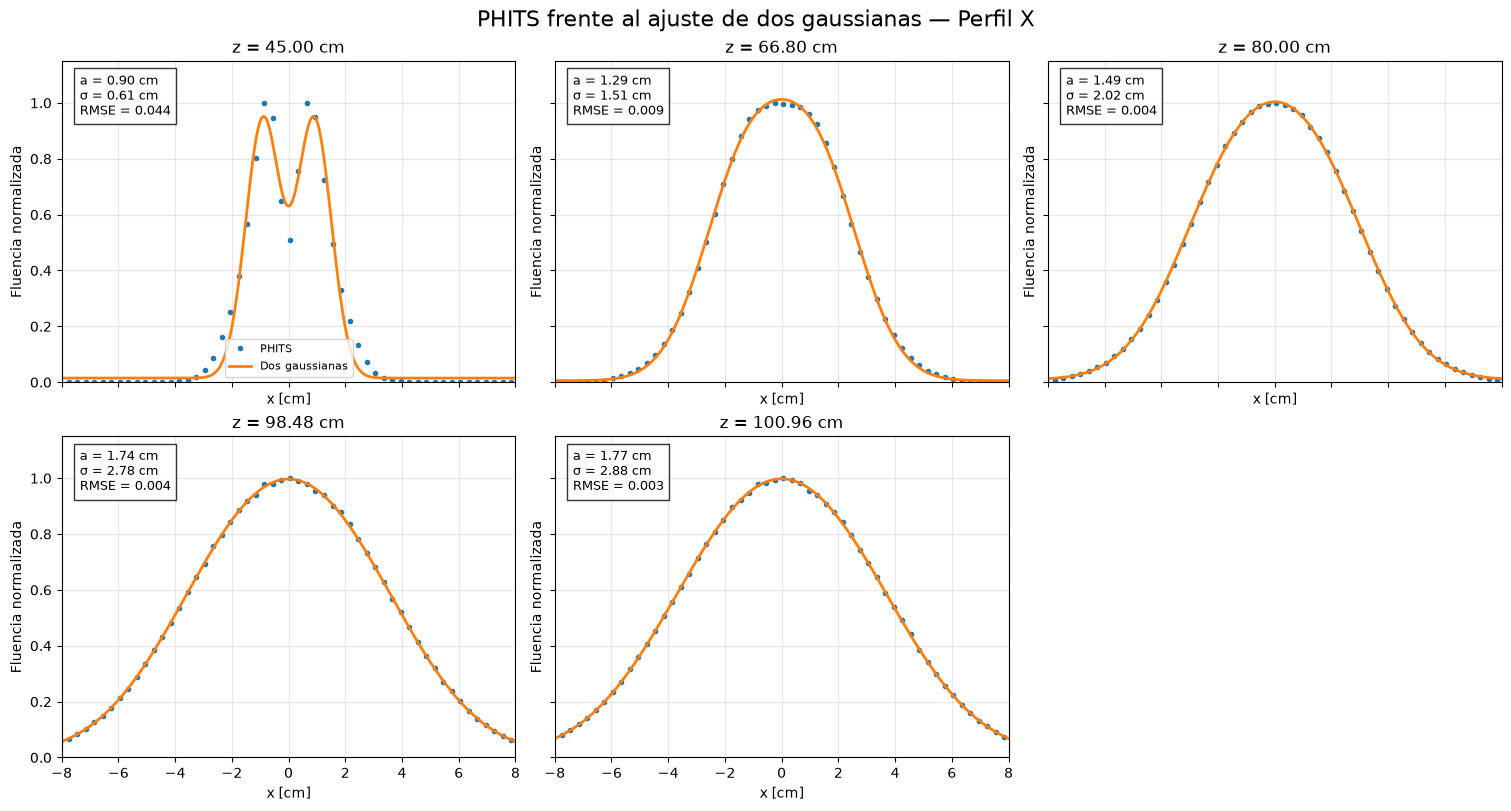

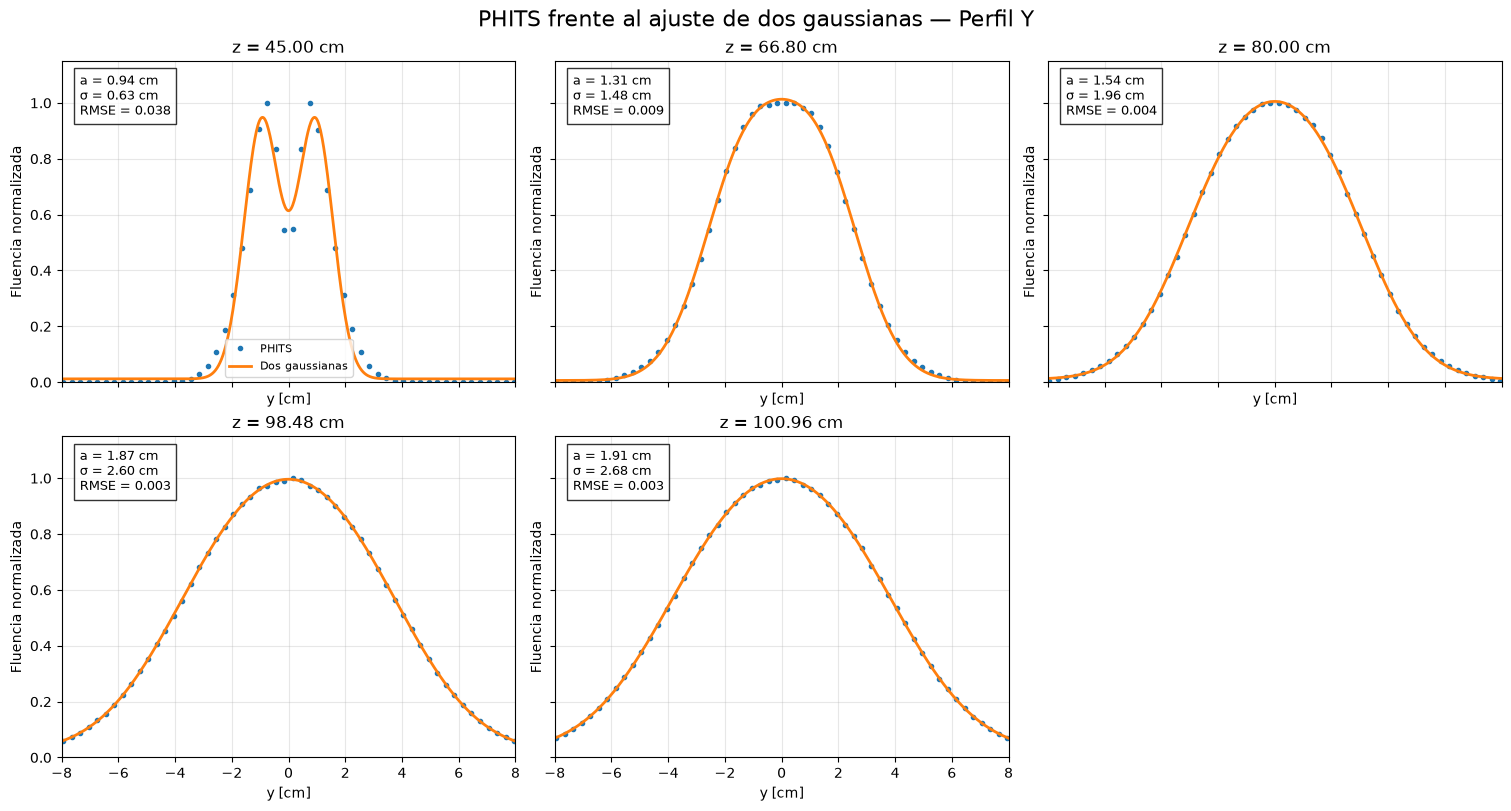

In [5]:
for eje in ('x', 'y'):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True, constrained_layout=True)
    for ax, r in zip(axes.flat, ajustes[eje]):
        u_fino = np.linspace(-8, 8, 600)
        modelo = dos_gaussianas(u_fino, r['A'], r['a'], r['sigma'], r['B'])
        ax.plot(r['coord'], r['perfil'] / r['escala'], 'o', markersize=3, label='PHITS')
        ax.plot(u_fino, modelo / r['escala'], '-', linewidth=2, label='Dos gaussianas')
        ax.set_title(f"z = {r['z']:.2f} cm")
        ax.set_xlim(-8, 8)
        ax.set_ylim(0, 1.15)
        ax.set_xlabel(f'{eje} [cm]')
        ax.set_ylabel('Fluencia normalizada')
        ax.grid(alpha=0.3)
        ax.text(0.04, 0.96, f"a = {r['a']:.2f} cm\nσ = {r['sigma']:.2f} cm\nRMSE = {r['RMSE']:.3f}", transform=ax.transAxes, va='top', fontsize=9, bbox=dict(facecolor='white', alpha=0.8))
    axes.flat[-1].axis('off')
    axes.flat[0].legend(loc='lower center', fontsize=8)
    fig.suptitle(f'PHITS frente al ajuste de dos gaussianas — Perfil {eje.upper()}', fontsize=16)
    plt.show()


## 5. Fusión de los máximos
El modelo cambia de mínimo a máximo central cuando a = σ. Las raíces entre planos son estimaciones por interpolación.

X: z* estimado = 57.542 cm
Y: z* estimado = 58.895 cm


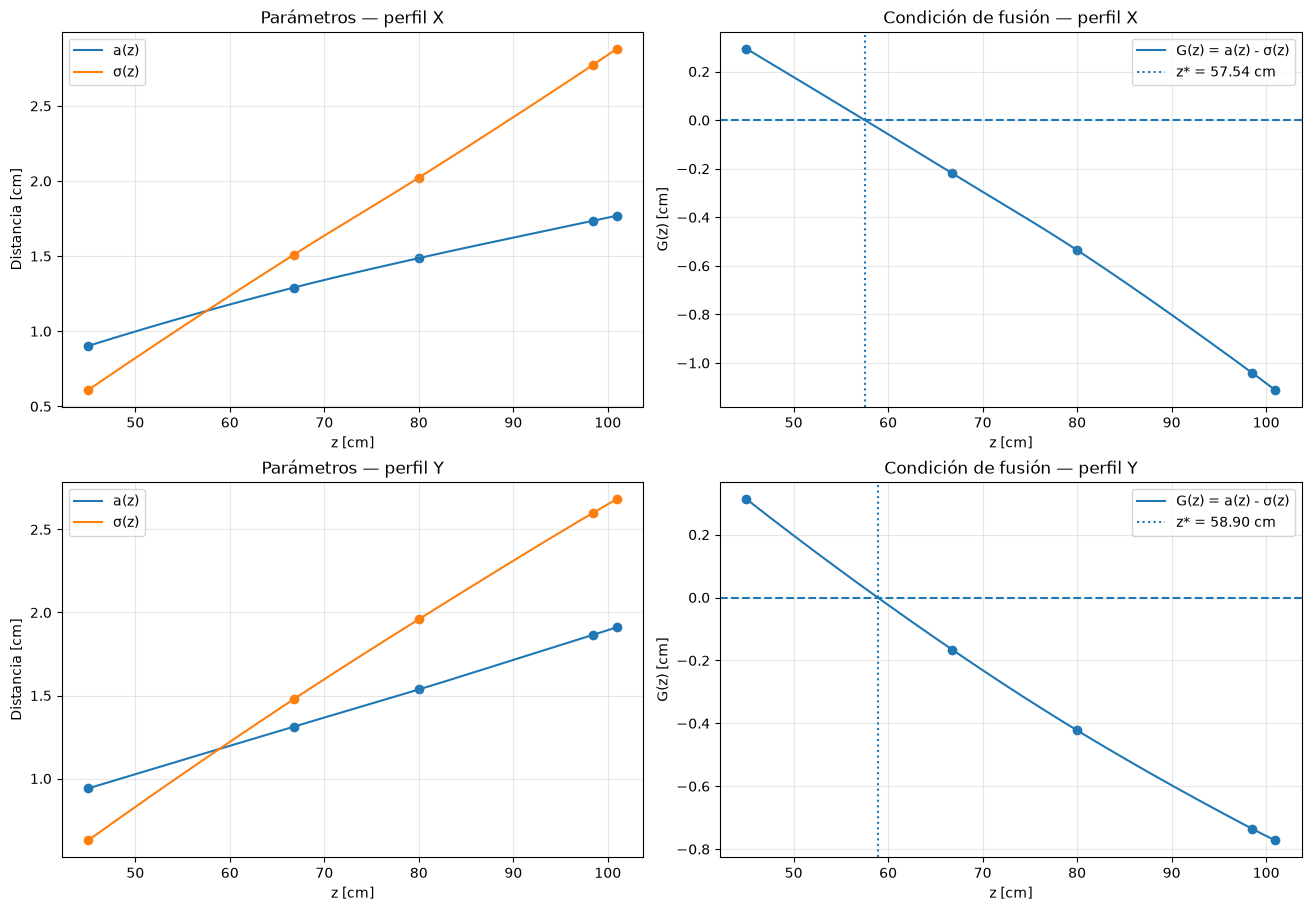

In [6]:
interpoladores = {}
for eje in ('x', 'y'):
    datos = ajustes[eje]
    z = np.array([r['z'] for r in datos])
    interpoladores[eje] = {'zmin': float(z.min()), 'zmax': float(z.max()), 'a': PchipInterpolator(z, [r['a'] for r in datos]), 'sigma': PchipInterpolator(z, [r['sigma'] for r in datos]), 'A': PchipInterpolator(z, [r['A'] for r in datos]), 'B': PchipInterpolator(z, [r['B'] for r in datos])}

def perfil_modelado(u, z, eje='x'):
    f = interpoladores[eje]
    if not f['zmin'] <= z <= f['zmax']:
        raise ValueError(f"z debe estar entre {f['zmin']} y {f['zmax']} cm; para alturas mayores usar perfil_extrapolado")
    return dos_gaussianas(np.asarray(u), float(f['A'](z)), float(f['a'](z)), float(f['sigma'](z)), float(f['B'](z)))
raices = {'x': [], 'y': []}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for fila, eje in enumerate(('x', 'y')):
    datos = ajustes[eje]
    f = interpoladores[eje]
    z_datos = np.array([r['z'] for r in datos])
    a_datos = np.array([r['a'] for r in datos])
    sigma_datos = np.array([r['sigma'] for r in datos])
    z_suave = np.linspace(f['zmin'], f['zmax'], 2000)
    a_suave = f['a'](z_suave)
    sigma_suave = f['sigma'](z_suave)
    G_suave = a_suave - sigma_suave
    ax1 = axes[fila, 0]
    ax1.plot(z_suave, a_suave, label='a(z)')
    ax1.plot(z_suave, sigma_suave, label='σ(z)')
    ax1.scatter(z_datos, a_datos)
    ax1.scatter(z_datos, sigma_datos)
    ax1.set(xlabel='z [cm]', ylabel='Distancia [cm]', title=f'Parámetros — perfil {eje.upper()}')
    ax1.grid(alpha=0.3)
    ax1.legend()
    ax2 = axes[fila, 1]
    ax2.plot(z_suave, G_suave, label='G(z) = a(z) - σ(z)')
    ax2.scatter(z_datos, a_datos - sigma_datos)
    ax2.axhline(0, linestyle='--')
    ax2.set(xlabel='z [cm]', ylabel='G(z) [cm]', title=f'Condición de fusión — perfil {eje.upper()}')
    ax2.grid(alpha=0.3)
    for i in range(len(z_suave) - 1):
        g1, g2 = (G_suave[i], G_suave[i + 1])
        if g1 * g2 < 0:
            raiz = brentq(lambda zz: float(f['a'](zz) - f['sigma'](zz)), z_suave[i], z_suave[i + 1])
            if not raices[eje] or abs(raiz - raices[eje][-1]) > 0.001:
                raices[eje].append(float(raiz))
                ax2.axvline(raiz, linestyle=':', label=f'z* = {raiz:.2f} cm')
    if raices[eje]:
        ax2.legend()
        print(f'{eje.upper()}: z* estimado = ' + ', '.join((f'{v:.3f} cm' for v in raices[eje])))
    else:
        print(f"{eje.upper()}: no se encontró a = σ entre {f['zmin']:.2f} y {f['zmax']:.2f} cm")
plt.show()


## 6. Comprobaciones con los datos
La curvatura depende de la ventana: ±1,5 cm puede abarcar los máximos de un valle estrecho y dar un signo engañoso. El umbral de depresión del 5 % se estima por interpolación lineal; no equivale a la fusión.

,z [cm],Curvatura X [cm^-2],Curvatura Y [cm^-2]
0,45.00,-0.04231,0.04232
1,66.80,-0.10447,-0.09335
2,80.00,-0.10510,-0.09163
3,98.48,-0.07747,-0.06730
4,100.96,-0.07523,-0.06321


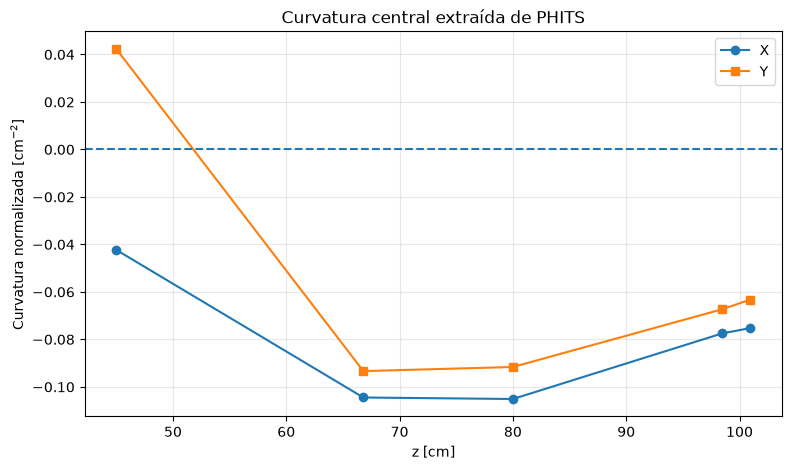

X: primera altura estimada con R >= 0.95: z ≈ 64.74 cm
Y: primera altura estimada con R >= 0.95: z ≈ 64.48 cm


In [7]:
def curvatura_central(coord, perfil, semiancho=1.5):
    mascara = np.abs(coord) <= semiancho
    u = np.asarray(coord[mascara])
    v = np.asarray(perfil[mascara])
    v = v / np.max(perfil)
    if len(u) < 4:
        raise ValueError('Hay muy pocos bins en el intervalo central')
    c2, c1, c0 = np.polyfit(u, v, deg=2)
    return float(2 * c2)
filas_curvatura = []
for r in resultados:
    if r['z'] < 40:
        continue
    filas_curvatura.append({'z [cm]': r['z'], 'Curvatura X [cm^-2]': curvatura_central(r['x'], r['perfil_x']), 'Curvatura Y [cm^-2]': curvatura_central(r['y'], r['perfil_y'])})
tabla_curvatura = pd.DataFrame(filas_curvatura)
display(tabla_curvatura.round(5))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_curvatura['z [cm]'], tabla_curvatura['Curvatura X [cm^-2]'], 'o-', label='X')
ax.plot(tabla_curvatura['z [cm]'], tabla_curvatura['Curvatura Y [cm^-2]'], 's-', label='Y')
ax.axhline(0, linestyle='--')
ax.set(xlabel='z [cm]', ylabel='Curvatura normalizada [cm$^{-2}$]', title='Curvatura central extraída de PHITS')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

def primera_altura_umbral(resultados, eje='x', umbral=0.95):
    pares = [(r['z'], r[f'r_{eje}']) for r in resultados if r['z'] >= 45]
    for (z1, r1), (z2, r2) in zip(pares[:-1], pares[1:]):
        if r1 < umbral <= r2:
            return float(z1 + (umbral - r1) * (z2 - z1) / (r2 - r1))
    return None
for eje in ('x', 'y'):
    z95 = primera_altura_umbral(resultados, eje=eje)
    if z95 is None:
        print(f'{eje.upper()}: no se encontró cruce ascendente de R = 0.95')
    else:
        print(f'{eje.upper()}: primera altura estimada con R >= 0.95: z ≈ {z95:.2f} cm')


## 7. Predicción a 110 y 120 cm
Se extrapolan a y σ linealmente con los últimos tres planos. A y B se extrapolan en logaritmo cuando son positivos. No incorporar datos nuevos al ajuste si se quiere validar esta predicción.

z=110.0 cm, X: a=1.8910 cm, sigma=3.2483 cm, a-sigma=-1.3573 cm, depresión=-0.00%
z=110.0 cm, Y: a=2.0722 cm, sigma=2.9980 cm, a-sigma=-0.9258 cm, depresión=-0.00%
z=120.0 cm, X: a=2.0257 cm, sigma=3.6570 cm, a-sigma=-1.6313 cm, depresión=-0.00%
z=120.0 cm, Y: a=2.2507 cm, sigma=3.3442 cm, a-sigma=-1.0935 cm, depresión=-0.00%


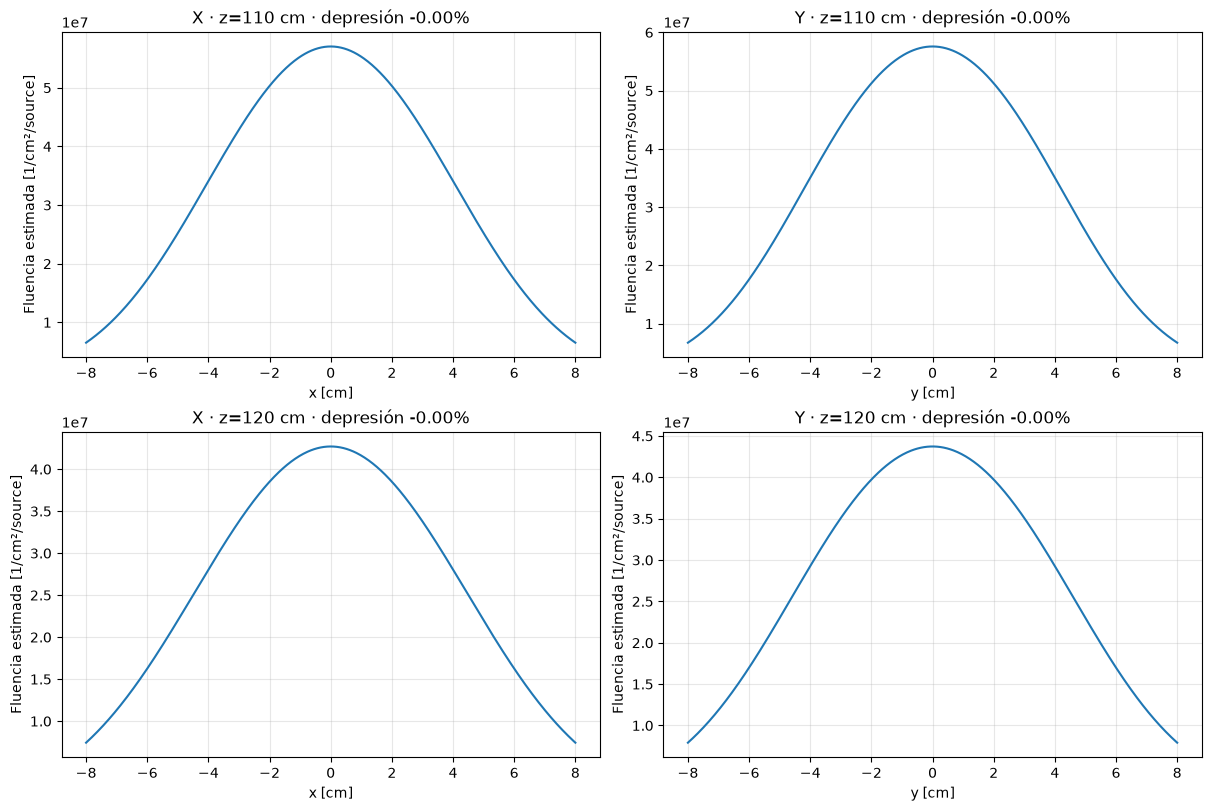

In [8]:
def parametros_extrapolados(eje, z):
    f = interpoladores[eje]
    if f['zmin'] <= z <= f['zmax']:
        return {k: float(f[k](z)) for k in ('A', 'a', 'sigma', 'B')}
    if z < f['zmin']:
        raise ValueError('La extrapolación está definida solo hacia posiciones posteriores al último T-Track')
    ultimos = ajustes[eje][-3:]
    alturas = np.array([r['z'] for r in ultimos], dtype=float)
    parametros = {}
    for nombre in ('a', 'sigma'):
        valores = np.array([r[nombre] for r in ultimos], dtype=float)
        pendiente, ordenada = np.polyfit(alturas, valores, 1)
        parametros[nombre] = float(pendiente * z + ordenada)
    for nombre in ('A', 'B'):
        valores = np.array([r[nombre] for r in ultimos], dtype=float)
        if np.all(valores > 0):
            pendiente, ordenada = np.polyfit(alturas, np.log(valores), 1)
            parametros[nombre] = float(np.exp(pendiente * z + ordenada))
        elif nombre == 'B':
            parametros[nombre] = max(0.0, float(valores[-1]))
        else:
            raise ValueError('Los valores de A no permiten extrapolación log-lineal')
    if parametros['a'] < 0 or parametros['sigma'] <= 0:
        raise ValueError(f'Los parámetros extrapolados en {z} cm dejaron de ser físicos')
    return parametros

def perfil_extrapolado(u, z, eje='x'):
    p = parametros_extrapolados(eje, z)
    return dos_gaussianas(np.asarray(u), p['A'], p['a'], p['sigma'], p['B'])
u = np.linspace(-8, 8, 600)
alturas_a_mostrar = [110.0, 120.0]
fig, axes = plt.subplots(len(alturas_a_mostrar), 2, figsize=(12, 8), constrained_layout=True)
for fila, z_prueba in enumerate(alturas_a_mostrar):
    for columna, eje in enumerate(('x', 'y')):
        p = parametros_extrapolados(eje, z_prueba)
        pred = perfil_extrapolado(u, z_prueba, eje=eje)
        centro = float(perfil_extrapolado(np.array([0.0]), z_prueba, eje=eje)[0])
        depresion = 100 * (1 - centro / np.max(pred))
        print(f"z={z_prueba:.1f} cm, {eje.upper()}: a={p['a']:.4f} cm, sigma={p['sigma']:.4f} cm, a-sigma={p['a'] - p['sigma']:.4f} cm, depresión={depresion:.2f}%")
        ax = axes[fila, columna]
        ax.plot(u, pred)
        ax.set(xlabel=f'{eje} [cm]', ylabel='Fluencia estimada [1/cm²/source]', title=f'{eje.upper()} · z={z_prueba:.0f} cm · depresión {depresion:.2f}%')
        ax.grid(alpha=0.3)
plt.show()


hice nuevas simulaciones - oclusor chico - a 110 y 120 cm para comparar con las predicciones del modelo anterior

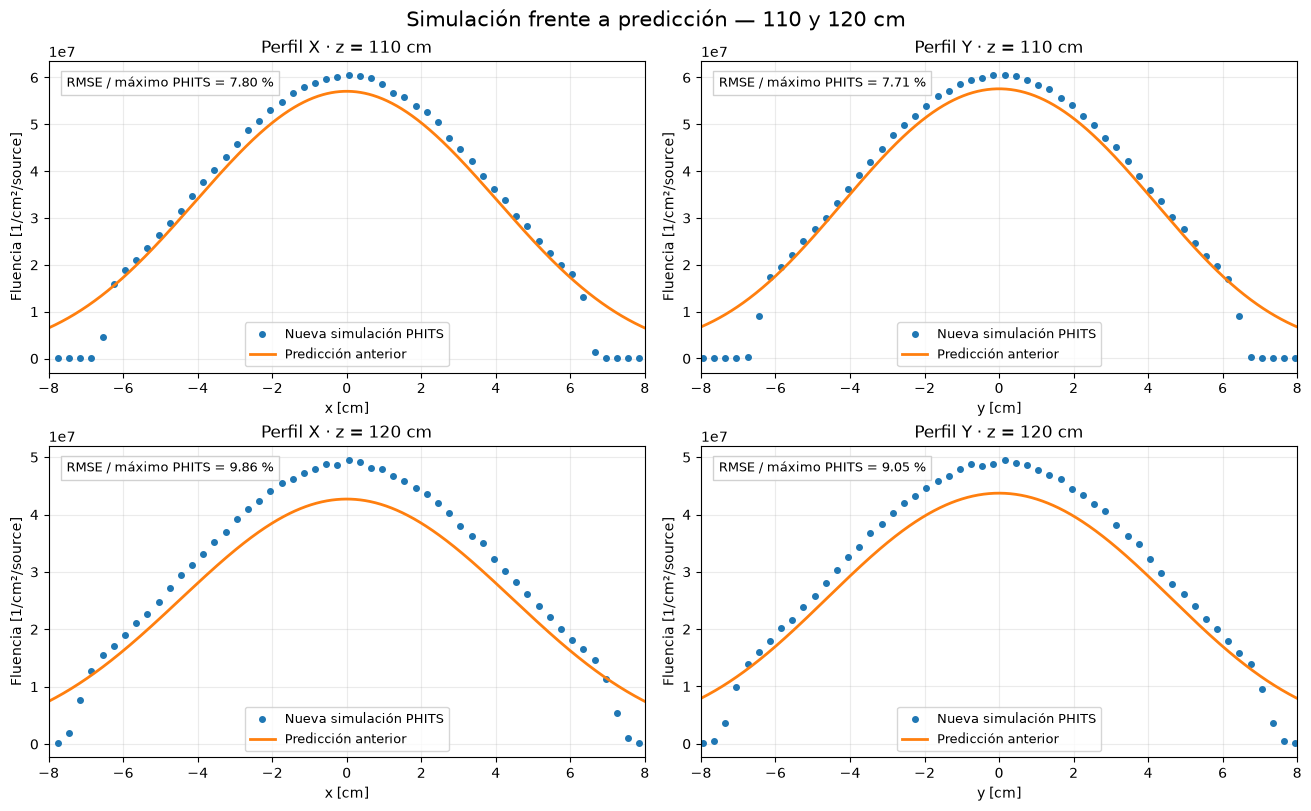

In [9]:
nuevos = [
    (110, "track_xy_110.out"),
    (120, "track_xy_120.out")
]

fig, axes = plt.subplots(
    2, 2, figsize=(13, 8), constrained_layout=True
)

u = np.linspace(-8, 8, 1001)

for fila, (z, nombre) in enumerate(nuevos):
    flujo, nx, ny = leer_ttrack(carpeta / nombre)
    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel

    perfiles = {
        "x": (x, flujo[np.argmin(abs(y)), :]),
        "y": (y, flujo[:, np.argmin(abs(x))])
    }

    for columna, (eje, (coord, perfil)) in enumerate(perfiles.items()):
        mascara = (abs(coord) <= 8) & np.isfinite(perfil)
        coord, perfil = coord[mascara], perfil[mascara]

        if perfil.size == 0 or perfil.max() <= 0:
            raise ValueError(f"Perfil {eje.upper()} inválido a {z} cm")

        pred = perfil_extrapolado(u, z, eje=eje)
        pred_bins = perfil_extrapolado(coord, z, eje=eje)
        rmse = 100 * np.sqrt(np.mean((perfil - pred_bins)**2)) / perfil.max()

        ax = axes[fila, columna]
        ax.plot(
            coord, perfil, "o", ms=4,
            color="tab:blue", label="Nueva simulación PHITS"
        )
        ax.plot(
            u, pred, lw=2,
            color="tab:orange", label="Predicción anterior"
        )
        ax.set(
            title=f"Perfil {eje.upper()} · z = {z} cm",
            xlabel=f"{eje} [cm]",
            ylabel="Fluencia [1/cm²/source]",
            xlim=(-8, 8)
        )
        ax.text(
            0.03, 0.95,
            f"RMSE / máximo PHITS = {rmse:.2f} %",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="0.8", alpha=0.9)
        )
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9, loc="lower center")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

fig.suptitle("Simulación frente a predicción — 110 y 120 cm", fontsize=15)
plt.show()

Las simulaciones con el oclusor más chico a 110 y 120 cm muestran perfiles con un máximo central, compatibles con la desaparición de la depresión prevista por el modelo. La extrapolación reproduce la forma general, pero subestima la fluencia central, especialmente a 120 cm, y no representa la caída abrupta en los extremos. El RMSE normalizado es cercano al 7,8 % a 110 cm y al 9–10 % a 120 cm. Aunque desaparece el mínimo central, los perfiles tienen forma de campana y no una meseta uniforme, por lo que debemos evaluar la variación de fluencia sobre el área del pouch para determinar si esta configuración resulta más conveniente.